In [1]:
# =========================
# Full RNN (LSTM) pipeline
# =========================
# !pip install optuna tensorflow scikit-learn pandas numpy matplotlib

import os
import numpy as np
import pandas as pd
from datetime import date

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import optuna
from optuna.integration import TFKerasPruningCallback

import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve, auc, RocCurveDisplay,
    precision_recall_curve, average_precision_score, PrecisionRecallDisplay
)


2025-10-16 20:24:27.566438: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-10-16 20:24:27.575281: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-10-16 20:24:27.583182: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-10-16 20:24:27.585662: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-10-16 20:24:27.592741: I tensorflow/core/platform/cpu_feature_guar

In [2]:
# ----------------------
# USER SETTINGS — EDIT ↓
# ----------------------
CSV_PATH     = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/with time/full sim data.csv"
NODE_COL     = "Mote ID"
TIME_COL     = "clock_time"      
SEQ_COL      = "seqno"           
LABEL_COL    = "isUnderAttack"   

# Features FEED TO THE MODEL 
FEATURE_COLS = [
    "cpu", "lpm", "transmit", "listen", "idle_listen",
    "all_cpu", "all_lpm", "all_transmit", "all_listen", "all_idle_listen",
]

# Sliding windows over time (your sampling is every 5s)
TIME_STEPS = 32   # 32*5s = 160 seconds of context per sample
STRIDE     = 4    # hop = 20 seconds

# Chronological split ratios (by window end-time)
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15   # test = 1 - TRAIN_FRAC - VAL_FRAC

# Number of target classes 
N_CLASSES  = 4


SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
# =======================================
# Helpers for time parsing & windowing
# =======================================
def _parse_clock_only_to_timestamp(s: str) -> pd.Timestamp:
   
    return pd.to_datetime(str(date(2000, 1, 1)) + " " + str(s))

def make_windows(arr_X, arr_y, time_idx, steps: int, stride: int):
   
    n = len(arr_X)
    Xs, ys, ts = [], [], []
    for start in range(0, n - steps + 1, stride):
        end = start + steps
        Xs.append(arr_X[start:end, :])
        ys.append(arr_y[end - 1])     # label policy = last step
        ts.append(time_idx[end - 1])  # window end-time
    if len(Xs) == 0:
        return (np.empty((0, steps, arr_X.shape[-1]), dtype=np.float32),
                np.empty((0,), dtype=np.int64),
                np.empty((0,), dtype="datetime64[ns]"))
    return np.stack(Xs), np.array(ys), np.array(ts)

In [4]:
# ==========================================
# Load CSV, order by time, build windows
# ==========================================
# 1) Load CSV
df = pd.read_csv(CSV_PATH)

# 2) Basic checks
required = {NODE_COL, TIME_COL, SEQ_COL, LABEL_COL}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

for c in FEATURE_COLS + [LABEL_COL]:
    if c not in df.columns:
        raise ValueError(f"Feature/label column '{c}' not found. Check FEATURE_COLS & LABEL_COL.")

# 3) Parse time and sort rows *within each node* by (time, seqno).

df["_parsed_time"] = df[TIME_COL].apply(_parse_clock_only_to_timestamp)
df.sort_values(by=[NODE_COL, "_parsed_time", SEQ_COL], inplace=True, kind="mergesort")
df.reset_index(drop=True, inplace=True)


df = df.dropna(subset=FEATURE_COLS + [LABEL_COL]).copy()

# 5) Build windows per node and stack them
X_list, y_list, t_list = [], [], []
for nid, g in df.groupby(NODE_COL, sort=False):
    Xg = g[FEATURE_COLS].to_numpy(dtype=np.float32)   
    yg = g[LABEL_COL].to_numpy(dtype=np.int64)
    tg = g["_parsed_time"].to_numpy()

    Xw, yw, tw = make_windows(Xg, yg, tg, steps=TIME_STEPS, stride=STRIDE)
    if len(Xw) > 0:
        X_list.append(Xw)
        y_list.append(yw)
        t_list.append(tw)

X = np.concatenate(X_list, axis=0) if X_list else np.empty((0, TIME_STEPS, len(FEATURE_COLS)), dtype=np.float32)
y = np.concatenate(y_list, axis=0) if y_list else np.empty((0,), dtype=np.int64)
t = np.concatenate(t_list, axis=0) if t_list else np.empty((0,), dtype="datetime64[ns]")

print("X shape:", X.shape, "y shape:", y.shape)  # e.g., (14418, 32, 10)

# 6) Chronological split by window end-time 
order = np.argsort(t)
X, y, t = X[order], y[order], t[order]

n_total = len(X)
n_train = int(n_total * TRAIN_FRAC)
n_val   = int(n_total * (TRAIN_FRAC + VAL_FRAC))


gap = 0  
n_train_gap_end = max(0, n_train - gap//2)
n_val_start     = min(n_total, n_train + gap//2)
n_val_gap_end   = max(n_val_start, n_val - gap//2)
n_test_start    = min(n_total, n_val + gap//2)

X_train, y_train = X[:n_train_gap_end], y[:n_train_gap_end]
X_val,   y_val   = X[n_val_start:n_val_gap_end], y[n_val_start:n_val_gap_end]
X_test,  y_test  = X[n_test_start:], y[n_test_start:]

print(f"Windows -> train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

scaler = StandardScaler()
X_train_2d = X_train.reshape(-1, X_train.shape[-1])
X_val_2d   = X_val.reshape(-1, X_val.shape[-1])
X_test_2d  = X_test.reshape(-1, X_test.shape[-1])

scaler.fit(X_train_2d)
X_train = scaler.transform(X_train_2d).reshape(X_train.shape)
X_val   = scaler.transform(X_val_2d).reshape(X_val.shape)
X_test  = scaler.transform(X_test_2d).reshape(X_test.shape)

# 8) Class weights for imbalance (macro-F1 focus).
classes_present = np.unique(y_train)
cw_vals = compute_class_weight(class_weight="balanced", classes=classes_present, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes_present, cw_vals)}
print("Class weights (train):", class_weights)

X shape: (14418, 32, 10) y shape: (14418,)
Windows -> train: 10092, val: 2163, test: 2163
Class weights (train): {0: 0.7336435010177377, 1: 1.1318977119784657, 2: 0.7650090964220739, 3: 2.2406749555950265}


In [5]:
# ==========================================
# LSTM builder + CV helper + objective
# ==========================================
def build_lstm(input_shape, n_classes, hp):
    """
    Build an LSTM model with tunable architecture and training parameters.
    Only the FEATURE_COLS (power-related) are fed into the model.
    """
    inputs = keras.Input(shape=input_shape)

    # ----- LSTM block 1 -----
    units1 = hp.suggest_categorical("units1", [32, 64, 96, 128, 192])
    bidir1 = hp.suggest_categorical("bidir1", [False, True])
    drop1  = hp.suggest_float("drop1", 0.0, 0.5)
    lstm1  = layers.LSTM(units1, return_sequences=True)
    x = layers.Bidirectional(lstm1)(inputs) if bidir1 else lstm1(inputs)
    x = layers.Dropout(drop1)(x)

    # ----- Optional LSTM block 2 -----
    use_second = hp.suggest_categorical("use_second", [False, True])
    if use_second:
        units2 = hp.suggest_categorical("units2", [32, 64, 96, 128, 192])
        bidir2 = hp.suggest_categorical("bidir2", [False, True])
        drop2  = hp.suggest_float("drop2", 0.0, 0.5)
        lstm2  = layers.LSTM(units2, return_sequences=False)
        x = layers.Bidirectional(lstm2)(x) if bidir2 else lstm2(x)
        x = layers.Dropout(drop2)(x)
    else:
        x = layers.GlobalAveragePooling1D()(x)

    # ----- Optional dense head -----
    dense_units = hp.suggest_categorical("dense_units", [0, 32, 64, 128, 256])
    if dense_units > 0:
        x = layers.Dense(dense_units, activation="relu")(x)
        x = layers.Dropout(hp.suggest_float("dense_drop", 0.0, 0.5))(x)

    # ----- Output layer -----
    if n_classes == 2:
        outputs = layers.Dense(1, activation="sigmoid")(x)
        loss = "binary_crossentropy"
    else:
        outputs = layers.Dense(n_classes, activation="softmax")(x)
        loss = "sparse_categorical_crossentropy"

    # ----- Optimizer -----
    lr = hp.suggest_float("lr", 1e-4, 1e-2, log=True)
    opt_choice = hp.suggest_categorical("optimizer", ["adam", "nadam", "rmsprop"])
    if opt_choice == "adam":
        opt = keras.optimizers.Adam(learning_rate=lr)
    elif opt_choice == "nadam":
        opt = keras.optimizers.Nadam(learning_rate=lr)
    else:
        opt = keras.optimizers.RMSprop(learning_rate=lr)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return model

def macro_f1_from_logits(y_true, y_pred_logits, n_classes):
    """Compute macro F1 from logits or probabilities."""
    if n_classes == 2:
        y_pred = (y_pred_logits.ravel() >= 0.5).astype(int)
    else:
        y_pred = np.argmax(y_pred_logits, axis=1)
    return f1_score(y_true, y_pred, average="macro")

def chrono_folds(n_samples, n_folds=3, gap=0):
    """Time-aware 3-fold CV with optional gap (to reduce near-duplicate overlap)."""
    idx = np.arange(n_samples)
    folds = np.array_split(idx, n_folds)
    pairs = []
    for k in range(n_folds):
        val_idx = folds[k]
        left  = idx[:max(0, val_idx[0] - gap)]
        right = idx[min(n_samples, val_idx[-1] + 1 + gap):]
        train_idx = np.concatenate([left, right])
        pairs.append((train_idx, val_idx))
    return pairs

def objective(trial: optuna.trial.Trial):
    hp = trial
    batch_size = hp.suggest_categorical("batch_size", [64, 128, 256, 512])
    epochs     = hp.suggest_int("epochs", 30, 120, step=10)

    folds = chrono_folds(len(X_train), n_folds=3, gap=TIME_STEPS)  # optional gap = TIME_STEPS
    f1s = []

    for fold_i, (tr_idx, va_idx) in enumerate(folds):
        model = build_lstm(input_shape=X_train.shape[1:], n_classes=N_CLASSES, hp=hp)

        callbacks = [
            keras.callbacks.EarlyStopping(
                monitor="val_loss", min_delta=1e-4, patience=10,
                restore_best_weights=True
            ),
            TFKerasPruningCallback(trial, monitor="val_loss")
        ]

        model.fit(
            X_train[tr_idx], y_train[tr_idx],
            validation_data=(X_train[va_idx], y_train[va_idx]),
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,
            class_weight=class_weights,
            callbacks=callbacks,
            shuffle=False
        )

        val_logits = model.predict(X_train[va_idx], batch_size=batch_size, verbose=0)
        f1_val = macro_f1_from_logits(y_train[va_idx], val_logits, N_CLASSES)
        f1s.append(f1_val)

        # Report intermediate mean F1 to enable pruning at the trial level
        trial.report(float(np.mean(f1s)), step=fold_i)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return 1.0 - float(np.mean(f1s))  # minimize 1 - macroF1

In [6]:
# ==========================================
# Run Optuna with Hyperband pruner
# ==========================================
pruner = optuna.pruners.HyperbandPruner(
    min_resource=5,     # min epochs considered
    max_resource=120,   # max epochs considered (must match search space upper bound)
    reduction_factor=3
)

study = optuna.create_study(direction="minimize", pruner=pruner)
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("\nBest trial:", study.best_trial.number)
print("Best value (1 - macroF1):", study.best_value)
print("Best params:")
for k, v in study.best_trial.params.items():
    print(f"  {k}: {v}")


[I 2025-10-16 20:24:44,527] A new study created in memory with name: no-name-587d84d5-7938-4957-9d4b-84916bff8223
  0%|                                                                                        | 0/40 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1760626484.963913   64814 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760626485.109110   64814 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760626485.109198   64814 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760626485.114117   64814 cuda_executor.cc:1001] could not open file to read 

/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 37 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 2 is already reported.
  warnings.warn(
Best trial: 0. Best value: 0.143989:   2%|█                                          | 1/40 [00:45<29:22, 45.18s/it]

[I 2025-10-16 20:25:29,711] Trial 0 finished with value: 0.14398870671226982 and parameters: {'batch_size': 512, 'epochs': 100, 'units1': 96, 'bidir1': True, 'drop1': 0.04552080356135435, 'use_second': False, 'dense_units': 64, 'dense_drop': 0.17099871336883776, 'lr': 0.0005127956187760337, 'optimizer': 'adam'}. Best is trial 0 with value: 0.14398870671226982.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 0 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 1 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 2 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 3 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501: UserWarning: The reported value is ignored because this `step` 4 is already reported.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/optuna/trial/_trial.py:501:

[I 2025-10-16 20:26:29,708] Trial 1 finished with value: 0.19146031430387545 and parameters: {'batch_size': 128, 'epochs': 50, 'units1': 192, 'bidir1': False, 'drop1': 0.03775714831994925, 'use_second': True, 'units2': 64, 'bidir2': False, 'drop2': 0.3959774822760304, 'dense_units': 128, 'dense_drop': 0.15827062072102183, 'lr': 0.004067868470006047, 'optimizer': 'adam'}. Best is trial 0 with value: 0.14398870671226982.


...

[I 2025-10-16 20:57:53,156] Trial 37 pruned. Trial was pruned at epoch 5.


Best trial: 14. Best value: 0.039418:  98%|███████████████████████████████████████▉ | 39/40 [33:17<00:23, 23.76s/it]

[I 2025-10-16 20:58:02,424] Trial 38 pruned. Trial was pruned at epoch 15.


Best trial: 14. Best value: 0.039418: 100%|█████████████████████████████████████████| 40/40 [33:30<00:00, 50.27s/it]

[I 2025-10-16 20:58:15,303] Trial 39 pruned. Trial was pruned at epoch 15.

Best trial: 14
Best value (1 - macroF1): 0.03941804306069763
Best params:
  batch_size: 64
  epochs: 120
  units1: 128
  bidir1: False
  drop1: 0.3716473223934011
  use_second: True
  units2: 96
  bidir2: False
  drop2: 0.2509831890697806
  dense_units: 256
  dense_drop: 0.021487288345838518
  lr: 0.0017998124064500603
  optimizer: nadam


In [7]:
# ==========================================
# Refit best model on TRAIN+VAL; evaluate TEST
# ==========================================
best_params = study.best_trial.params

class _HP:
    """Adapter to reuse build_lstm() with fixed best params."""
    def __init__(self, params): self.p = params
    def suggest_categorical(self, name, choices): return self.p[name]
    def suggest_float(self, name, low, high, log=False): return self.p[name]
    def suggest_int(self, name, low, high, step=1): return self.p[name]

hp_best = _HP(best_params)
best_model = build_lstm(X_train.shape[1:], N_CLASSES, hp_best)

batch_size = best_params["batch_size"]
epochs     = best_params["epochs"]

# Merge TRAIN + VAL for final fit
X_trval = np.concatenate([X_train, X_val], axis=0)
y_trval = np.concatenate([y_train, y_val], axis=0)

# Recalculate class weights on TRAIN+VAL
classes_tv = np.unique(y_trval)
cw_vals_tv = compute_class_weight(class_weight="balanced", classes=classes_tv, y=y_trval)
cw_tv = {int(c): float(w) for c, w in zip(classes_tv, cw_vals_tv)}

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", min_delta=1e-4, patience=10, restore_best_weights=True
    )
]

# Small internal holdout (10%) from the END of tr+val to emulate chronology
val_hold_frac = 0.10
n_tv = len(X_trval)
n_tv_val = max(1, int(n_tv * val_hold_frac))
X_tr, y_tr = X_trval[:-n_tv_val], y_trval[:-n_tv_val]
X_hold, y_hold = X_trval[-n_tv_val:], y_trval[-n_tv_val:]

hist = best_model.fit(
    X_tr, y_tr,
    validation_data=(X_hold, y_hold),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1,
    class_weight=cw_tv,
    callbacks=callbacks,
    shuffle=False
)


Epoch 1/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7844 - loss: 0.4578 - val_accuracy: 0.9265 - val_loss: 0.1393
Epoch 2/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8918 - loss: 0.3486 - val_accuracy: 0.9265 - val_loss: 0.1343
Epoch 3/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9636 - loss: 0.1097 - val_accuracy: 0.9290 - val_loss: 0.1068
Epoch 4/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9436 - loss: 0.1951 - val_accuracy: 1.0000 - val_loss: 0.0895
Epoch 5/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9811 - loss: 0.0646 - val_accuracy: 1.0000 - val_loss: 0.0309
Epoch 6/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9775 - loss: 0.0747 - val_accuracy: 1.0000 - val_loss: 0.0082
Epoch 7/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9845 - loss: 0.0524 - val_accuracy: 1.0000 - val_loss: 7.9295e-04
Epoch 8/120
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9749 - loss: 0.092

In [8]:
# ===== Final Test Evaluation =====
test_logits = best_model.predict(X_test, batch_size=batch_size, verbose=0)
if N_CLASSES == 2:
    y_pred = (test_logits.ravel() >= 0.5).astype(int)
else:
    y_pred = np.argmax(test_logits, axis=1)

print("\n===== TEST RESULTS =====")
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred, digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


===== TEST RESULTS =====
Macro F1: 0.9820132727109472
              precision    recall  f1-score   support

           0     1.0000    0.9567    0.9779      1040
           1     1.0000    1.0000    1.0000       487
           2     0.9051    1.0000    0.9502       429
           3     1.0000    1.0000    1.0000       207

    accuracy                         0.9792      2163
   macro avg     0.9763    0.9892    0.9820      2163
weighted avg     0.9812    0.9792    0.9795      2163

Confusion matrix:
 [[995   0  45   0]
 [  0 487   0   0]
 [  0   0 429   0]
 [  0   0   0 207]]


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/utils/_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


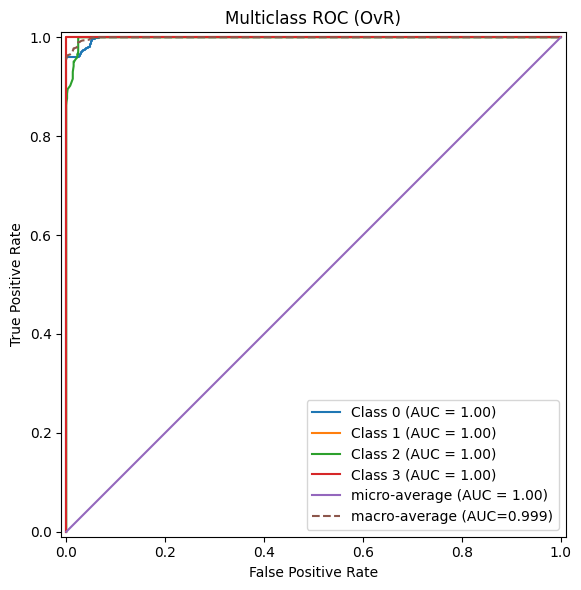

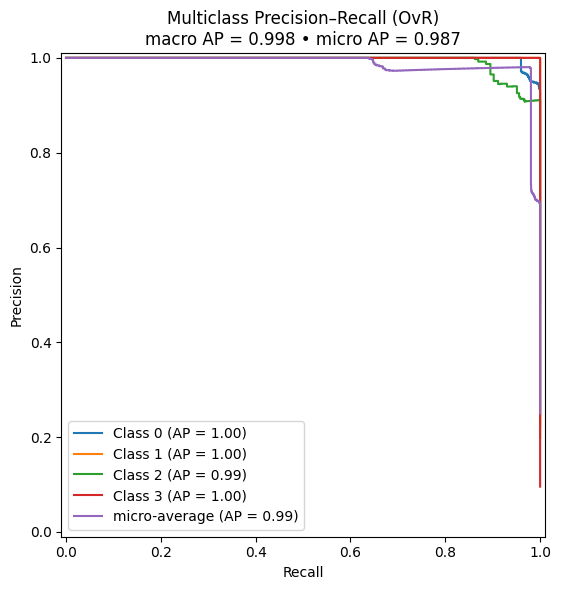

=== ROC-AUC ===
micro: 0.9952 | macro: 0.9991
  class 0: 0.9983
  class 1: 1.0000
  class 2: 0.9981
  class 3: 1.0000

=== PR-AUC (Average Precision) ===
micro: 0.9867 | macro: 0.9977
  class 0: 0.9982
  class 1: 1.0000
  class 2: 0.9925
  class 3: 1.0000


In [9]:
# ===== Optional: ROC & PR curves (multiclass OvR) =====
y_true = y_test
y_score = test_logits  # softmax probabilities in multiclass

classes = np.unique(y_true)
n_classes_present = len(classes)
if y_score.shape[1] != N_CLASSES:
    raise ValueError(f"Model output has shape {y_score.shape}, but N_CLASSES={N_CLASSES}")

# Reindex probabilities to the present classes 
y_score_reindexed = y_score[:, classes] if not np.array_equal(classes, np.arange(N_CLASSES)) else y_score

Y_bin = label_binarize(y_true, classes=classes)  # shape (n_samples, n_classes_present)

# ROC
fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes_present):
    fpr[i], tpr[i], _ = roc_curve(Y_bin[:, i], y_score_reindexed[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fpr["micro"], tpr["micro"], _ = roc_curve(Y_bin.ravel(), y_score_reindexed[:, :n_classes_present].ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes_present)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes_present):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes_present
roc_auc["macro"] = auc(all_fpr, mean_tpr)

plt.figure(figsize=(7, 6))
for i in range(n_classes_present):
    RocCurveDisplay(fpr=fpr[i], tpr=tpr[i], roc_auc=roc_auc[i],
                    estimator_name=f"Class {classes[i]}").plot(ax=plt.gca())
RocCurveDisplay(fpr=fpr["micro"], tpr=fpr["micro"], roc_auc=roc_auc["micro"],
                estimator_name="micro-average").plot(ax=plt.gca())
plt.plot(all_fpr, mean_tpr, linestyle="--", label=f"macro-average (AUC={roc_auc['macro']:.3f})")
plt.title("Multiclass ROC (OvR)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# PR
prec, rec, ap = {}, {}, {}
for i in range(n_classes_present):
    prec[i], rec[i], _ = precision_recall_curve(Y_bin[:, i], y_score_reindexed[:, i])
    ap[i] = average_precision_score(Y_bin[:, i], y_score_reindexed[:, i])

prec["micro"], rec["micro"], _ = precision_recall_curve(Y_bin.ravel(), y_score_reindexed[:, :n_classes_present].ravel())
ap["micro"] = average_precision_score(Y_bin, y_score_reindexed[:, :n_classes_present], average="micro")
ap["macro"] = average_precision_score(Y_bin, y_score_reindexed[:, :n_classes_present], average="macro")

plt.figure(figsize=(7, 6))
for i in range(n_classes_present):
    PrecisionRecallDisplay(precision=prec[i], recall=rec[i],
                           average_precision=ap[i],
                           estimator_name=f"Class {classes[i]}").plot(ax=plt.gca())
PrecisionRecallDisplay(precision=prec["micro"], recall=rec["micro"],
                       average_precision=ap["micro"],
                       estimator_name="micro-average").plot(ax=plt.gca())
plt.title(f"Multiclass Precision–Recall (OvR)\nmacro AP = {ap['macro']:.3f} • micro AP = {ap['micro']:.3f}")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

print("=== ROC-AUC ===")
print(f"micro: {roc_auc['micro']:.4f} | macro: {roc_auc['macro']:.4f}")
for i in range(n_classes_present):
    print(f"  class {classes[i]}: {roc_auc[i]:.4f}")

print("\n=== PR-AUC (Average Precision) ===")
print(f"micro: {ap['micro']:.4f} | macro: {ap['macro']:.4f}")
for i in range(n_classes_present):
    print(f"  class {classes[i]}: {ap[i]:.4f}")

In [10]:
# =========================
# Save artifacts to disk
# =========================
import json, joblib, pathlib, datetime

OUT_DIR = pathlib.Path("artifacts_lstm")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1) Keras model (do NOT pickle the model itself)
best_model.save(OUT_DIR / "lstm_model.keras")  
best_model.save(OUT_DIR / "lstm_model.h5")     

# 2) Preprocessor
joblib.dump(scaler, OUT_DIR / "scaler.pkl")

# 3) Best hyperparams and meta
meta = {
    "created_at": datetime.datetime.utcnow().isoformat() + "Z",
    "n_classes": int(N_CLASSES),
    "time_steps": int(TIME_STEPS),
    "stride": int(STRIDE),
    "feature_cols": FEATURE_COLS,
    "label_col": LABEL_COL,
    "train_frac": TRAIN_FRAC,
    "val_frac": VAL_FRAC,
    "class_weights_train": class_weights,
    "best_params": best_params,
    "final_test": {
        "macro_f1": float(f1_score(y_test, y_pred, average="macro")),
        "classification_report_digits": 4
    }
}
with open(OUT_DIR / "metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

# 4) (Optional) Save the Optuna study (picklable)
joblib.dump(study, OUT_DIR / "optuna_study.pkl")

print(f"\nArtifacts saved to: {OUT_DIR.resolve()}")



Artifacts saved to: /home/ubuntu1/projects/MPhilCodes/artifacts_lstm


In [11]:
# =========================
# Optional: pickle a wrapper
# =========================
import cloudpickle
from dataclasses import dataclass

@dataclass
class LSTMInferenceWrapper:
    model_path: str
    scaler_path: str
    feature_cols: list
    time_steps: int

    def _lazy_load(self):
        if not hasattr(self, "_model"):
            self._model = keras.models.load_model(self.model_path)
            self._scaler = joblib.load(self.scaler_path)

    def predict_proba(self, X_seq_3d):
        """
        X_seq_3d: (n_samples, time_steps, n_features) already windowed
        """
        self._lazy_load()
        # scale per-feature across time like during training
        shp = X_seq_3d.shape
        X_2d = X_seq_3d.reshape(-1, shp[-1])
        X_scaled = self._scaler.transform(X_2d).reshape(shp)
        return self._model.predict(X_scaled, verbose=0)

    def predict(self, X_seq_3d):
        proba = self.predict_proba(X_seq_3d)
        if proba.shape[1] == 1:
            return (proba.ravel() >= 0.5).astype(int)
        return np.argmax(proba, axis=1)

wrapper = LSTMInferenceWrapper(
    model_path=str(OUT_DIR / "lstm_model.keras"),
    scaler_path=str(OUT_DIR / "scaler.pkl"),
    feature_cols=FEATURE_COLS,
    time_steps=TIME_STEPS
)

with open(OUT_DIR / "inference_wrapper.pkl", "wb") as f:
    cloudpickle.dump(wrapper, f)

print("Pickled wrapper saved:", OUT_DIR / "inference_wrapper.pkl")


Pickled wrapper saved: artifacts_lstm/inference_wrapper.pkl
